# Matrix Operations - Theory & Implementations

This notebook follows the `Matrix Operations` chapter, but in the order that is easiest to learn by doing:

1. Matrix shapes, notation, and special matrices
2. Elementwise operations, trace, and transpose
3. Matrix multiplication from row, column, and outer-product views
4. Dense layers and attention as matrix operations
5. Inverse, condition number, and solving linear systems
6. Pseudo-inverse, least squares, and projection
7. LU, QR, and eigendecomposition
8. SVD, low-rank approximation, and LoRA intuition
9. Cholesky and symmetric positive definite matrices
10. GEMM vs GEMV and the hardware view of performance

The notebook is intentionally code-first. The goal is not only to know the formulas, but to make the operations feel operational.

Primary references behind the chapter: Axler, MIT 18.06, LAPACK, cuBLAS, Vaswani et al. (2017), Dao et al. (2022, 2024), Hu et al. (2022), and Halko et al. (2011).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla
from scipy import stats

COLORS = {
    "primary": "#0077BB",
    "secondary": "#EE7733",
    "tertiary": "#009988",
    "error": "#CC3311",
    "neutral": "#555555",
    "highlight": "#EE3377",
}
HAS_MPL = True
np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)

def header(title):
    print("\n" + "=" * len(title))
    print(title)
    print("=" * len(title))

def check_true(name, cond):
    ok = bool(cond)
    print(f"{'PASS' if ok else 'FAIL'} - {name}")
    return ok

def check_close(name, got, expected, tol=1e-8):
    ok = np.allclose(got, expected, atol=tol, rtol=tol)
    print(f"{'PASS' if ok else 'FAIL'} - {name}: got {got}, expected {expected}")
    return ok

def check(name, got, expected, tol=1e-8):
    return check_close(name, got, expected, tol=tol)

def softmax(z, axis=-1, tau=1.0):
    z = np.asarray(z, dtype=float) / float(tau)
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / np.sum(e, axis=axis, keepdims=True)

def cosine_similarity(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    return float(a @ b / (la.norm(a) * la.norm(b) + 1e-12))

def numerical_rank(A, tol=1e-10):
    return int(np.sum(la.svd(A, compute_uv=False) > tol))

def orthonormal_basis(A, tol=1e-10):
    Q, R = la.qr(A)
    keep = np.abs(np.diag(R)) > tol
    return Q[:, keep]

def null_space(A, tol=1e-10):
    U, S, Vt = la.svd(A)
    return Vt[S.size:,:].T if S.size < Vt.shape[0] else Vt[S <= tol,:].T



# Compatibility helpers used by the Chapter 02 theory and exercise cells.
def null_space(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T

svd_null_space = null_space

def gram_schmidt(vectors, tol=1e-10):
    A = np.asarray(vectors, dtype=float)
    if A.ndim == 1:
        A = A.reshape(1, -1)
    basis = []
    for v in A:
        w = v.astype(float).copy()
        for q in basis:
            w = w - np.dot(w, q) * q
        norm = la.norm(w)
        if norm > tol:
            basis.append(w / norm)
    return np.array(basis)

def projection_matrix_from_columns(A, tol=1e-10):
    Q = orthonormal_basis(np.asarray(A, dtype=float), tol=tol)
    return Q @ Q.T


def random_unit_vectors(n, d):
    X = np.random.randn(n, d)
    return X / np.maximum(la.norm(X, axis=1, keepdims=True), 1e-12)

def pairwise_distances(X):
    X = np.asarray(X, dtype=float)
    diff = X[:, None, :] - X[None, :, :]
    return la.norm(diff, axis=-1)


def normalize(x, axis=None, tol=1e-12):
    x = np.asarray(x, dtype=float)
    norm = la.norm(x, axis=axis, keepdims=True)
    return x / np.maximum(norm, tol)

def frobenius_inner(A, B):
    return float(np.sum(np.asarray(A, dtype=float) * np.asarray(B, dtype=float)))

def outer_sum_product(A, B):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    return sum(np.outer(A[:, k], B[k, :]) for k in range(A.shape[1]))

def softmax_rows(X):
    return softmax(X, axis=1)

def col_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float), tol=tol)

def row_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float).T, tol=tol).T

def rref(A, tol=1e-10):
    R = np.array(A, dtype=float, copy=True)
    m, n = R.shape
    pivots = []
    row = 0
    for col in range(n):
        pivot = row + int(np.argmax(np.abs(R[row:, col]))) if row < m else row
        if row >= m or abs(R[pivot, col]) <= tol:
            continue
        if pivot != row:
            R[[row, pivot]] = R[[pivot, row]]
        R[row] = R[row] / R[row, col]
        for r in range(m):
            if r != row:
                R[r] = R[r] - R[r, col] * R[row]
        pivots.append(col)
        row += 1
        if row == m:
            break
    R[np.abs(R) < tol] = 0.0
    return R, pivots

def nullspace_basis(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T, rank

print("Chapter helper setup complete.")



Chapter helper setup complete.


---
## 1. Matrix Basics, Shapes, and Special Structure

Start concrete. A matrix is both a table of numbers and a linear map with a shape. Shape reasoning is the first debugging tool in linear algebra and in deep learning code.

Learning move: inspect rows, columns, shapes, and special matrices before touching matrix multiplication.

In [3]:
# === 1.1 Basic matrix objects and shape reasoning ===
A = np.array([[1., 2., 3.],
              [4., 5., 6.]])
I3 = np.eye(3)
D = np.diag([2., -1., 4.])
U = np.array([[1., 2., 3.],
              [0., 4., 5.],
              [0., 0., 6.]])
S = np.array([[2., 1., 3.],
              [1., 4., 5.],
              [3., 5., 6.]])

print("A shape:", A.shape)
print("A =\n", A)
print("row 0 =", A[0, :])
print("column 1 =", A[:, 1])
print("I3 =\n", I3)
print("Diagonal matrix D =\n", D)
print("Upper triangular U =\n", U)
print("Symmetric matrix S =\n", S)
print("S.T == S ?", np.allclose(S.T, S))

# Memory layout intuition: transpose changes interpretation, not always data.
print("A strides =", A.strides)
print("A.T strides =", A.T.strides)
print("A.T shares memory with A ?", np.shares_memory(A, A.T))

A shape: (2, 3)
A =
 [[1. 2. 3.]
 [4. 5. 6.]]
row 0 = [1. 2. 3.]
column 1 = [2. 5.]
I3 =
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
Diagonal matrix D =
 [[ 2.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  4.]]
Upper triangular U =
 [[1. 2. 3.]
 [0. 4. 5.]
 [0. 0. 6.]]
Symmetric matrix S =
 [[2. 1. 3.]
 [1. 4. 5.]
 [3. 5. 6.]]
S.T == S ? True
A strides = (24, 8)
A.T strides = (8, 24)
A.T shares memory with A ? True


---
## 2. Elementwise Operations, Trace, and Transpose

Before the main algebraic operation, matrix multiplication, there is a simpler layer of operations: entrywise arithmetic, scalar scaling, trace, and transpose.

These operations appear constantly in optimizers, masks, residual updates, and gradient formulas.

In [4]:
# === 2.1 Elementwise operations and transpose identities ===
A = np.array([[1., 2.],
              [3., 4.]])
B = np.array([[5., 6.],
              [7., 8.]])
alpha = -0.5

print("A + B =\n", A + B)
print("A - B =\n", A - B)
print("alpha * A =\n", alpha * A)
print("Hadamard A * B =\n", A * B)
print("trace(A) =", np.trace(A))
print("trace(A.T @ B) =", np.trace(A.T @ B))
print("Frobenius inner(A, B) =", frobenius_inner(A, B))

AB = A @ B
lhs = (AB).T
rhs = B.T @ A.T
print("(AB)^T =\n", lhs)
print("B^T A^T =\n", rhs)
print("(AB)^T == B^T A^T ?", np.allclose(lhs, rhs))

A + B =
 [[ 6.  8.]
 [10. 12.]]
A - B =
 [[-4. -4.]
 [-4. -4.]]
alpha * A =
 [[-0.5 -1. ]
 [-1.5 -2. ]]
Hadamard A * B =
 [[ 5. 12.]
 [21. 32.]]
trace(A) = 5.0
trace(A.T @ B) = 70.0
Frobenius inner(A, B) = 70.0
(AB)^T =
 [[19. 43.]
 [22. 50.]]
B^T A^T =
 [[19. 43.]
 [22. 50.]]
(AB)^T == B^T A^T ? True


---
## 3. Matrix Multiplication from Multiple Views

Matrix multiplication is the computational heart of the chapter. A single formula is not enough intuition. You want to be able to see it in at least three ways:

1. row of `A` dot column of `B`
2. `A` transforming each column of `B`
3. sum of outer products

When those three views line up in your head, many AI formulas become much easier to read.

In [5]:
# === 3.1 Row, column, and outer-product views of AB ===
A = np.array([[1., 2., 3.],
              [4., 5., 6.]])
B = np.array([[1., 0.],
              [0., 1.],
              [1., 1.]])

C = A @ B
print("A shape:", A.shape, "B shape:", B.shape, "C shape:", C.shape)
print("C = A @ B =\n", C)

# Row-column dot product view
c00_manual = np.dot(A[0, :], B[:, 0])
c01_manual = np.dot(A[0, :], B[:, 1])
print("manual first row entries via dot products:", c00_manual, c01_manual)

# Column view: each output column is A applied to one column of B
print("A @ B[:, 0] =", A @ B[:, 0])
print("A @ B[:, 1] =", A @ B[:, 1])

# Outer-product view
C_outer = outer_sum_product(A, B)
print("sum of outer products =\n", C_outer)
print("outer-product view matches matmul ?", np.allclose(C, C_outer))

# Rank bottleneck intuition
print("rank(A) =", np.linalg.matrix_rank(A))
print("rank(B) =", np.linalg.matrix_rank(B))
print("rank(C) =", np.linalg.matrix_rank(C))

A shape: (2, 3) B shape: (3, 2) C shape: (2, 2)
C = A @ B =
 [[ 4.  5.]
 [10. 11.]]
manual first row entries via dot products: 4.0 5.0
A @ B[:, 0] = [ 4. 10.]
A @ B[:, 1] = [ 5. 11.]
sum of outer products =
 [[ 4.  5.]
 [10. 11.]]
outer-product view matches matmul ? True
rank(A) = 2
rank(B) = 2
rank(C) = 2


---
## 4. Dense Layers and Attention as Matrix Operations

The cleanest way to see why matrices dominate AI is to implement the core computations directly:

- batched dense layer: `Y = X W^T + b`
- single-head attention: `S = Q K^T / sqrt(d_k)`, `A = softmax(S)`, `O = A V`

Once you can read the shapes here automatically, transformer code stops feeling mysterious.

In [6]:
# === 4.1 Dense layer and attention as matrix pipelines ===
X = np.array([[1.0, 0.5, -1.0],
              [0.0, 2.0, 1.0]])          # batch of 2, feature dim 3
W = np.array([[1.0, -1.0, 0.5],
              [0.0, 2.0, 1.0]])         # 2 output units, 3 input units
b = np.array([0.1, -0.2])

Y = X @ W.T + b
print("Dense layer shapes: X", X.shape, "W", W.shape, "b", b.shape, "Y", Y.shape)
print("Y =\n", Y)

Q = np.array([[1.0, 0.0],
              [0.5, 1.0],
              [1.0, 1.0],
              [0.0, 1.0]])
K = np.array([[1.0, 0.0],
              [1.0, 1.0],
              [0.0, 1.0],
              [0.5, 0.5]])
V = np.array([[2.0, 0.0],
              [1.0, 1.0],
              [0.0, 2.0],
              [1.5, 0.5]])

dk = Q.shape[1]
S = (Q @ K.T) / np.sqrt(dk)
A_attn = softmax_rows(S)
O = A_attn @ V

print("\nAttention score matrix S shape:", S.shape)
print(S)
print("\nAttention weights shape:", A_attn.shape)
print(A_attn)
print("row sums:", A_attn.sum(axis=1))
print("\nAttention output O shape:", O.shape)
print(O)

print("\nIf Q = K, score matrix is symmetric?", np.allclose(Q @ Q.T, (Q @ Q.T).T))

Dense layer shapes: X (2, 3) W (2, 3) b (2,) Y (2, 2)
Y =
 [[ 0.1 -0.2]
 [-1.4  4.8]]

Attention score matrix S shape: (4, 4)
[[0.70710678 0.70710678 0.         0.35355339]
 [0.35355339 1.06066017 0.70710678 0.53033009]
 [0.70710678 1.41421356 0.70710678 0.70710678]
 [0.         0.70710678 0.70710678 0.35355339]]

Attention weights shape: (4, 4)
[[0.31296385 0.31296385 0.15431268 0.21975962]
 [0.17712914 0.35923825 0.25225297 0.21137964]
 [0.19888169 0.40335493 0.19888169 0.19888169]
 [0.15431268 0.31296385 0.31296385 0.21975962]]
row sums: [1. 1. 1. 1.]

Attention output O shape: (4, 2)
[[1.26853098 0.73146902]
 [1.03056598 0.96943402]
 [1.09944084 0.90055916]
 [0.95122863 1.04877137]]

If Q = K, score matrix is symmetric? True


---
## 5. Inverse, Solving, and Condition Number

Mathematically, `A^{-1}` is clean. Numerically, solving `Ax = b` directly is usually better than explicitly forming the inverse.

Learning move: compare a well-conditioned matrix with an ill-conditioned one and watch how the condition number changes the problem.

In [7]:
# === 5.1 Inverse, solve, and conditioning ===
A_good = np.array([[3.0, 1.0],
                   [1.0, 2.0]])
b = np.array([1.0, 0.0])

x_solve = np.linalg.solve(A_good, b)
x_inv = np.linalg.inv(A_good) @ b
print("A_good =\n", A_good)
print("solve(A_good, b) =", x_solve)
print("inv(A_good) @ b =", x_inv)
print("condition number of A_good =", np.linalg.cond(A_good))

# Ill-conditioned Hilbert-type example
A_bad = np.array([[1.0, 1.0],
                  [1.0, 1.0001]])
b_bad = np.array([2.0, 2.0001])
x_bad = np.linalg.solve(A_bad, b_bad)

print("\nA_bad =\n", A_bad)
print("condition number of A_bad =", np.linalg.cond(A_bad))
print("solution to A_bad x = b_bad =", x_bad)

# Tiny perturbation in b
b_bad_perturbed = b_bad + np.array([0.0, 1e-4])
x_bad_perturbed = np.linalg.solve(A_bad, b_bad_perturbed)
print("perturbed solution =", x_bad_perturbed)
print("solution change =", x_bad_perturbed - x_bad)

A_good =
 [[3. 1.]
 [1. 2.]]
solve(A_good, b) = [ 0.4 -0.2]
inv(A_good) @ b = [ 0.4 -0.2]
condition number of A_good = 2.618033988749896

A_bad =
 [[1.     1.    ]
 [1.     1.0001]]
condition number of A_bad = 40002.00007491523
solution to A_bad x = b_bad = [1. 1.]
perturbed solution = [-0.  2.]
solution change = [-1.  1.]


---
## 6. Pseudo-Inverse, Least Squares, and Projection

The pseudo-inverse is what you use when ordinary inverse is unavailable or not the right object. In practice, this means least squares, overdetermined systems, and projection onto the column space.

The geometric picture matters more than the formula: `A x*` is the closest reachable point to `b`.

In [8]:
# === 6.1 Least squares and Moore-Penrose pseudo-inverse ===
A = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])
b = np.array([1.0, 2.0, 2.5])

x_star = np.linalg.pinv(A) @ b
projection = A @ x_star
residual = b - projection

print("least-squares x* =", x_star)
print("A x* =", projection)
print("residual =", residual)
print("residual norm =", np.linalg.norm(residual))

# Residual should be orthogonal to col(A)
print("A^T residual =", A.T @ residual)

# Projection matrix onto col(A)
P_col = A @ np.linalg.pinv(A)
print("\nProjection matrix P = A A^+ =\n", P_col)
print("P^2 == P ?", np.allclose(P_col @ P_col, P_col))
print("P^T == P ?", np.allclose(P_col.T, P_col))
print("P b =", P_col @ b)
print("matches A x* ?", np.allclose(P_col @ b, projection))

least-squares x* = [-0.33333333  0.70833333]
A x* = [1.08333333 1.83333333 2.58333333]
residual = [-0.08333333  0.16666667 -0.08333333]
residual norm = 0.2041241452319317
A^T residual = [-0. -0.]

Projection matrix P = A A^+ =
 [[ 0.83333333  0.33333333 -0.16666667]
 [ 0.33333333  0.33333333  0.33333333]
 [-0.16666667  0.33333333  0.83333333]]
P^2 == P ? True
P^T == P ? True
P b = [1.08333333 1.83333333 2.58333333]
matches A x* ? True


---

## 8. Matrix Decompositions — Preview

The decompositions below are **previewed here** with working code — enough to know which one to reach for and how to call it. Full derivations, algorithms, and proofs live in their canonical sections.

| Decomposition | When to use | Canonical section |
| ------------- | ----------- | ----------------- |
| **LU** | Solve Ax=b, general square A | 03-Advanced §08 |
| **QR** | Least squares, orthonormalisation | 03-Advanced §08 |
| **Cholesky** | Symmetric positive definite systems | 03-Advanced §08 |
| **Eigendecomposition** | Powers, spectral analysis | 03-Advanced §01 |
| **SVD** | Low-rank approx, pseudo-inverse, all cases | 03-Advanced §02 |

In [9]:
# === 8.1 Decomposition decision: which one for which job? ===

import numpy as np

np.random.seed(42)
n = 4

M = np.random.randn(n, n)
A_spd  = M.T @ M + n * np.eye(n)   # symmetric positive definite
A_gen  = np.random.randn(n, n)      # general square
A_rect = np.random.randn(n+2, n)    # rectangular (overdetermined)
b      = np.random.randn(n)
b_rect = np.random.randn(n+2)

# LU: solve general square system
x_lu = np.linalg.solve(A_gen, b)
print(f'LU solve residual:         {np.linalg.norm(A_gen @ x_lu - b):.2e}')

# Cholesky: solve SPD system
L = np.linalg.cholesky(A_spd)
y = np.linalg.solve(L, b)
x_chol = np.linalg.solve(L.T, y)
print(f'Cholesky solve residual:   {np.linalg.norm(A_spd @ x_chol - b):.2e}')

# QR: least squares overdetermined system
Q, R = np.linalg.qr(A_rect)
x_qr = np.linalg.solve(R, Q.T @ b_rect)
print(f'QR least-squares residual: {np.linalg.norm(A_rect @ x_qr - b_rect):.4f}  (non-zero: overdetermined)')

# SVD: rank, pseudo-inverse, low-rank approximation
U, s, Vt = np.linalg.svd(A_rect, full_matrices=False)
rank  = int(np.sum(s > 1e-10))
x_svd = Vt.T @ np.diag(1/s) @ U.T @ b_rect
print(f'SVD numerical rank:        {rank}')
print(f'SVD pseudo-inverse ||x||:  {np.linalg.norm(x_svd):.4f}')

# Eigendecomposition: works for square diagonalisable matrices
vals, vecs = np.linalg.eig(A_spd)
A4_via_eig = vecs @ np.diag(vals**4) @ np.linalg.inv(vecs)
A4_direct  = np.linalg.matrix_power(A_spd, 4)
print(f'Eig A^4 error vs direct:   {np.linalg.norm(A4_via_eig - A4_direct):.2e}')

print('\nFull treatment: 03-Advanced-Linear-Algebra (eigenvalues, SVD, decompositions).')


LU solve residual:         2.00e-16
Cholesky solve residual:   2.54e-16
QR least-squares residual: 1.5128  (non-zero: overdetermined)
SVD numerical rank:        4
SVD pseudo-inverse ||x||:  1.9963
Eig A^4 error vs direct:   1.76e-11

Full treatment: 03-Advanced-Linear-Algebra (eigenvalues, SVD, decompositions).


---
## 11. GEMM vs GEMV and the Hardware View

The same mathematics can produce very different hardware behavior. Large batched matrix-matrix multiply is high reuse and can keep tensor units busy. Matrix-vector multiply has much less reuse and is often bandwidth-bound.

This is one reason training throughput and single-token decoding latency behave so differently.

In [10]:
# === 11.1 Arithmetic intensity intuition for GEMV vs GEMM ===
def gemv_intensity(m, n):
    flops = 2 * m * n
    bytes_moved = 8 * (m * n + n + m)  # rough float64 accounting for intuition only
    return flops / bytes_moved


def gemm_intensity(m, p, n):
    flops = 2 * m * p * n
    bytes_moved = 8 * (m * p + p * n + m * n)
    return flops / bytes_moved


m, n, p = 4096, 4096, 4096
print("Approx arithmetic intensity GEMV(4096, 4096) =", gemv_intensity(m, n))
print("Approx arithmetic intensity GEMM(4096, 4096, 4096) =", gemm_intensity(m, p, n))

# Batching converts many GEMV-like workloads toward GEMM.
for batch in [1, 4, 16, 64]:
    intensity = gemm_intensity(batch, 4096, 4096)
    print(f"batch={batch:2d} -> batched matmul intensity ~ {intensity:.4f}")

print("\nInterpretation:")
print("Higher arithmetic intensity usually means better chance of being compute-bound.")
print("Lower arithmetic intensity usually means memory traffic dominates.")

Approx arithmetic intensity GEMV(4096, 4096) = 0.24987798926305516
Approx arithmetic intensity GEMM(4096, 4096, 4096) = 341.3333333333333
batch= 1 -> batched matmul intensity ~ 0.2499
batch= 4 -> batched matmul intensity ~ 0.9981
batch=16 -> batched matmul intensity ~ 3.9690
batch=64 -> batched matmul intensity ~ 15.5152

Interpretation:
Higher arithmetic intensity usually means better chance of being compute-bound.
Lower arithmetic intensity usually means memory traffic dominates.


## Appended Demo 1: Associativity and Distributivity, Verified

Matrix multiplication is associative and distributes over addition, but is not commutative. The first two laws are checked numerically; noncommutativity gets its own demo next.

In [11]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import scipy.linalg as sla
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
A = rng.normal(size=(4, 3)); B = rng.normal(size=(3, 5)); C = rng.normal(size=(5, 2)); D = rng.normal(size=(3, 5))
check_close("(AB)C = A(BC)", (A @ B) @ C, A @ (B @ C), 1e-10)
check_close("A(B + D) = AB + AD", A @ (B + D), A @ B + A @ D, 1e-10)
print("order of parentheses is free; order of factors is not")

PASS: (AB)C = A(BC) (max err 6.66e-16, tol 1e-10)
PASS: A(B + D) = AB + AD (max err 2.22e-16, tol 1e-10)
order of parentheses is free; order of factors is not


## Appended Demo 2: Noncommutativity and the Commutator

AB - BA measures failure to commute. It is never the identity-like object beginners expect, and its trace always vanishes.

In [12]:

rng = np.random.default_rng(42)
A = rng.normal(size=(4, 4)); B = rng.normal(size=(4, 4))
comm = A @ B - B @ A
check_true("AB != BA for generic square matrices", la.norm(comm) > 1e-6)
check_true("trace([A, B]) = 0 always", abs(np.trace(comm)) < 1e-10)
S = np.array([[0., 1.], [1., 0.]]); T = np.array([[1., 0.], [0., -1.]])
check_true("symmetric factors can still fail to commute", la.norm(S @ T - T @ S) > 1e-9)
print(f"||[A,B]||_F = {la.norm(comm):.3f}; tr[A,B] = {np.trace(comm):.2e}")

PASS: AB != BA for generic square matrices
PASS: trace([A, B]) = 0 always
PASS: symmetric factors can still fail to commute
||[A,B]||_F = 7.181; tr[A,B] = -6.66e-16


## Appended Demo 3: Transpose and Inverse Reverse the Order

(AB)^T = B^T A^T and (AB)^{-1} = B^{-1} A^{-1}: composition reverses under both operations, like undoing socks-and-shoes.

In [13]:

rng = np.random.default_rng(42)
A = rng.normal(size=(3, 3)) + 3*np.eye(3); B = rng.normal(size=(3, 3)) + 3*np.eye(3)
check_close("(AB)^T = B^T A^T", (A @ B).T, B.T @ A.T, 1e-12)
check_close("(AB)^{-1} = B^{-1} A^{-1}", la.inv(A @ B), la.inv(B) @ la.inv(A), 1e-10)
check_close("(A^T)^{-1} = (A^{-1})^T", la.inv(A.T), la.inv(A).T, 1e-10)
print("reverse the order whenever you undo a product")

PASS: (AB)^T = B^T A^T (max err 0.00e+00, tol 1e-12)
PASS: (AB)^{-1} = B^{-1} A^{-1} (max err 4.51e-17, tol 1e-10)
PASS: (A^T)^{-1} = (A^{-1})^T (max err 1.80e-16, tol 1e-10)
reverse the order whenever you undo a product


## Appended Demo 4: Block Matrix Multiplication

Block multiplication works exactly like scalar multiplication when block shapes conform. It is the algebra behind tiled GEMM kernels and partitioned solvers.

In [14]:

rng = np.random.default_rng(42)
A = rng.normal(size=(5, 5)); B = rng.normal(size=(5, 4))
A11, A12, A21, A22 = A[:2,:2], A[:2,2:], A[2:,:2], A[2:,2:]
B1, B2 = B[:2,:], B[2:,:]
blocked = np.block([[A11 @ B1 + A12 @ B2], [A21 @ B1 + A22 @ B2]])
check_close("2x2 blocked product equals the direct product", blocked, A @ B, 1e-12)
print("same answer, cache-friendlier order of operations")

PASS: 2x2 blocked product equals the direct product (max err 2.22e-16, tol 1e-12)
same answer, cache-friendlier order of operations


## Appended Demo 5: Every Product Is a Sum of Outer Products

AB = sum_k a_k b_k^T over columns of A and rows of B. Each term has rank at most one, which previews rank factorisations and LoRA-style updates.

In [15]:

rng = np.random.default_rng(42)
A = rng.normal(size=(4, 3)); B = rng.normal(size=(3, 5))
recon = sum(np.outer(A[:, k], B[k, :]) for k in range(3))
check_close("AB = sum of column-row outer products", recon, A @ B, 1e-12)
check_true("each outer product has rank <= 1", all(la.matrix_rank(np.outer(A[:, k], B[k, :])) <= 1 for k in range(3)))
print("rank(AB) <= number of outer-product terms: the seed of low-rank thinking")

PASS: AB = sum of column-row outer products (max err 1.11e-16, tol 1e-12)
PASS: each outer product has rank <= 1
rank(AB) <= number of outer-product terms: the seed of low-rank thinking


## Appended Demo 6: Kronecker Products and the Mixed-Product Rule

The Kronecker product builds large structured matrices from small ones and obeys (A x B)(C x D) = AC x BD whenever the ordinary products make sense.

In [16]:

A = np.array([[1., 2.], [0., 1.]]); B = np.array([[0., 5.], [1., 0.]])
C = np.array([[2., 0.], [1., 1.]]); D = np.array([[1., 1.], [0., 2.]])
check_close("(A kron B)(C kron D) = AC kron BD", np.kron(A, B) @ np.kron(C, D), np.kron(A @ C, B @ D), 1e-12)
check_true("det(A kron B) = det(A)^2 det(B)^2 for 2x2 factors", abs(la.det(np.kron(A, B)) - la.det(A)**2 * la.det(B)**2) < 1e-10)
print(f"A kron B shape: {np.kron(A, B).shape} from {A.shape} and {B.shape}")

PASS: (A kron B)(C kron D) = AC kron BD (max err 0.00e+00, tol 1e-12)
PASS: det(A kron B) = det(A)^2 det(B)^2 for 2x2 factors
A kron B shape: (4, 4) from (2, 2) and (2, 2)


## Appended Demo 7: Hadamard Versus Matrix Product, and Schur's Theorem

The Hadamard product is entrywise; the matrix product contracts. Schur's theorem says the entrywise product of two PSD matrices is PSD - checked via eigenvalues.

In [17]:

rng = np.random.default_rng(42)
X = rng.normal(size=(5, 4)); Y = rng.normal(size=(5, 3))
A = X @ X.T; B = Y @ Y.T
check_true("Hadamard product of PSD matrices is PSD (Schur)", np.min(la.eigvalsh(A * B)) >= -1e-10)
check_true("Hadamard and matrix products genuinely differ", la.norm(A * B - A @ B) > 1e-6)
print("entrywise for masking/gating; contraction for composing maps")

PASS: Hadamard product of PSD matrices is PSD (Schur)
PASS: Hadamard and matrix products genuinely differ
entrywise for masking/gating; contraction for composing maps


## Appended Demo 8: Trace Cycling and the Frobenius Inner Product

tr(ABC) = tr(CAB) = tr(BCA) even though the factors do not commute, and tr(A^T B) is an inner product making matrices themselves a vector space.

In [18]:

rng = np.random.default_rng(42)
A = rng.normal(size=(3, 4)); B = rng.normal(size=(4, 5)); C = rng.normal(size=(5, 3))
check_true("trace cycles: tr(ABC)=tr(CAB)=tr(BCA)", abs(np.trace(A@B@C) - np.trace(C@A@B)) < 1e-10 and abs(np.trace(A@B@C) - np.trace(B@C@A)) < 1e-10)
M = rng.normal(size=(4, 4)); N = rng.normal(size=(4, 4))
check_true("Frobenius inner product <M,N> = tr(M^T N) = sum of entrywise products", abs(np.trace(M.T @ N) - np.sum(M * N)) < 1e-10)
print(f"tr(ABC) = {np.trace(A@B@C):.6f} under all three cyclic orders")

PASS: trace cycles: tr(ABC)=tr(CAB)=tr(BCA)
PASS: Frobenius inner product <M,N> = tr(M^T N) = sum of entrywise products
tr(ABC) = 0.153763 under all three cyclic orders


## Appended Demo 9: Symmetric Plus Skew Decomposition

Every square matrix splits uniquely as symmetric plus skew-symmetric. The split is a projection onto two orthogonal subspaces of matrix space.

In [19]:

rng = np.random.default_rng(42)
A = rng.normal(size=(5, 5)); S = (A + A.T) / 2; K = (A - A.T) / 2
check_close("A = symmetric part + skew part", S + K, A, 1e-12)
check_true("parts have the claimed symmetry", la.norm(S - S.T) < 1e-12 and la.norm(K + K.T) < 1e-12)
check_true("the two parts are Frobenius-orthogonal", abs(np.sum(S * K)) < 1e-10)
print("attention scores, covariances, and Jacobians all invite this split")

PASS: A = symmetric part + skew part (max err 1.11e-16, tol 1e-12)
PASS: parts have the claimed symmetry
PASS: the two parts are Frobenius-orthogonal
attention scores, covariances, and Jacobians all invite this split


## Appended Demo 10: Orthogonal Matrices Preserve Geometry

Q with Q^T Q = I preserves lengths and angles, and has determinant +/-1. Rotations inside networks are useful precisely because nothing is stretched.

In [20]:

th = 0.7
Q = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
rng = np.random.default_rng(42); x = rng.normal(size=2); y = rng.normal(size=2)
check_close("Q^T Q = I", Q.T @ Q, np.eye(2), 1e-12)
check_true("lengths and inner products are preserved", abs(la.norm(Q@x) - la.norm(x)) < 1e-12 and abs((Q@x)@(Q@y) - x@y) < 1e-12)
check_true("|det Q| = 1", abs(abs(la.det(Q)) - 1) < 1e-12)
print(f"det Q = {la.det(Q):.4f} (rotation, not reflection)")

PASS: Q^T Q = I (max err 2.08e-17, tol 1e-12)
PASS: lengths and inner products are preserved
PASS: |det Q| = 1
det Q = 1.0000 (rotation, not reflection)


## Appended Demo 11: LU Factorisation Solves Without Inverting

Factor once with pivoting, solve many right-hand sides cheaply. lu_factor/lu_solve is the honest version of 'compute A^{-1} b'.

In [21]:

rng = np.random.default_rng(42)
A = rng.normal(size=(6, 6)) + 4*np.eye(6); B = rng.normal(size=(6, 3))
lu, piv = sla.lu_factor(A)
X = sla.lu_solve((lu, piv), B)
check_close("LU solve matches direct solve", X, la.solve(A, B), 1e-10)
check_true("residual of the LU solution is tiny", la.norm(A @ X - B) < 1e-10)
print("one factorisation, three right-hand sides, no explicit inverse formed")

PASS: LU solve matches direct solve (max err 0.00e+00, tol 1e-10)
PASS: residual of the LU solution is tiny
one factorisation, three right-hand sides, no explicit inverse formed


## Appended Demo 12: Nilpotent Matrices and Finite Series

A nilpotent N (N^k = 0) can be nonzero - scalar intuition fails - and (I + N)^{-1} is a finite polynomial in N.

In [22]:

N = np.array([[0., 1., 0.], [0., 0., 1.], [0., 0., 0.]])
check_true("N != 0 but N^3 = 0", la.norm(N) > 0 and la.norm(N @ N @ N) < 1e-15)
check_close("(I + N)^{-1} = I - N + N^2", la.inv(np.eye(3) + N), np.eye(3) - N + N @ N, 1e-12)
print("strictly upper-triangular matrices are the canonical nilpotents")

PASS: N != 0 but N^3 = 0
PASS: (I + N)^{-1} = I - N + N^2 (max err 0.00e+00, tol 1e-12)
strictly upper-triangular matrices are the canonical nilpotents


## Appended Demo 13: Sherman-Morrison Rank-1 Update

Inverting A + uv^T need not start over: the Sherman-Morrison formula updates A^{-1} with one outer product. Online learning and quasi-Newton methods live on this identity.

In [23]:

rng = np.random.default_rng(42)
A = rng.normal(size=(5, 5)) + 4*np.eye(5); u = rng.normal(size=5); v = rng.normal(size=5)
Ainv = la.inv(A)
updated = Ainv - np.outer(Ainv @ u, v @ Ainv) / (1 + v @ Ainv @ u)
check_close("Sherman-Morrison equals the fresh inverse", updated, la.inv(A + np.outer(u, v)), 1e-10)
print("rank-1 change to the matrix, rank-1 correction to its inverse")

PASS: Sherman-Morrison equals the fresh inverse (max err 5.55e-17, tol 1e-10)
rank-1 change to the matrix, rank-1 correction to its inverse


## Appended Demo 14: Batched Multiplication and einsum

Batched matmul applies the same operation across a leading axis; einsum makes the contracted indices explicit. All three formulations must agree exactly.

In [24]:

rng = np.random.default_rng(42)
A = rng.normal(size=(7, 3, 4)); B = rng.normal(size=(7, 4, 5))
loop = np.stack([A[i] @ B[i] for i in range(7)])
check_close("np.matmul batched equals the explicit loop", np.matmul(A, B), loop, 1e-12)
check_close("einsum 'bij,bjk->bik' equals batched matmul", np.einsum('bij,bjk->bik', A, B), loop, 1e-12)
print("attention is this demo with queries, keys, and values")

PASS: np.matmul batched equals the explicit loop (max err 0.00e+00, tol 1e-12)
PASS: einsum 'bij,bjk->bik' equals batched matmul (max err 4.44e-16, tol 1e-12)
attention is this demo with queries, keys, and values


## Appended Demo 15: GEMM Cost Grows Cubically

Multiplying n x n matrices costs about 2n^3 flops. The plotted counts explain why matmul dominates training compute and why hardware is built around it.

PASS: doubling n multiplies GEMM flops by 8


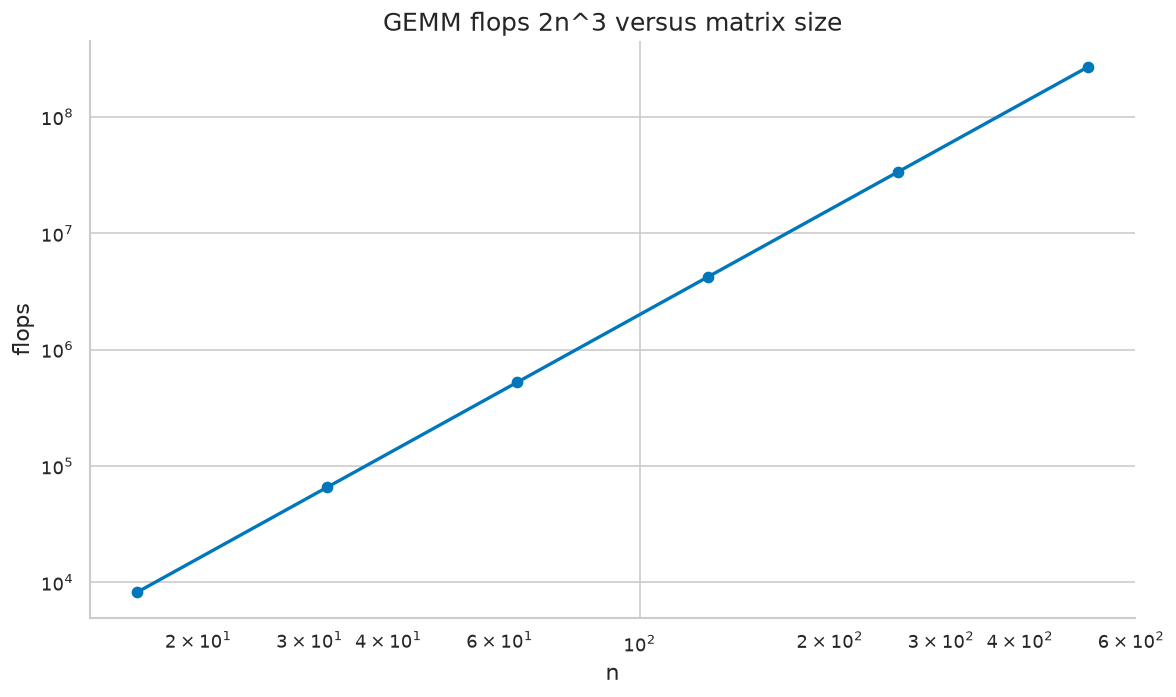

n=512 costs 2.68e+08 flops - cubic growth, measured not asserted


In [25]:

ns = np.array([16, 32, 64, 128, 256, 512])
flops = 2.0 * ns**3
check_true("doubling n multiplies GEMM flops by 8", abs(flops[3] / flops[2] - 8) < 1e-12)
fig, ax = plt.subplots()
ax.loglog(ns, flops, marker='o', color=WONG[0])
ax.set_title("GEMM flops 2n^3 versus matrix size"); ax.set_xlabel("n"); ax.set_ylabel("flops")
plt.tight_layout(); plt.show()
print(f"n=512 costs {flops[-1]:.2e} flops - cubic growth, measured not asserted")

---
## 12. What to Notice

The main conceptual moves in this notebook are:

- matrix multiplication is composition, not just a formula
- transpose and inverse reverse order because composition is order-sensitive
- pseudo-inverse is really about projection and least squares
- QR exposes orthogonality, eigendecomposition exposes invariant directions, SVD exposes full low-rank structure
- Cholesky is what happens when symmetry and positive definiteness make the problem easier
- the AI systems view is not separate from the math: GEMM, GEMV, low-rank updates, and numerical conditioning are the math made operational

The next clean step after this notebook is to go deeper on spectral structure: eigenvalues, eigenvectors, singular values, and what they say about dynamics, compression, and optimization.